# COM7022 Machine Learning – Task 1
## Part 3: Robustness Checks and Report Figures
**Input:** `sales_clean.csv` (output of Part 1) and, for the missing-value chart, the raw dataset.

This notebook responds to the formative feedback. It:
1. identifies outliers explicitly with the **IQR method** and compares clustering **before and after** treating them;
2. examines the **cluster separation** behind the modest silhouette score;
3. tests **stability on different samples** of the data (subsampling and bootstrap), not only different random seeds;
4. tests whether **product size** and **update history** would add value as features;
5. saves **compact, consistently titled figures** to a `figures/` folder for the report.

In [1]:
import glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
K = 4
os.makedirs('figures', exist_ok=True)

# Consistent, compact figure style for the report
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 9, 'axes.titlesize': 10,
    'axes.labelsize': 9, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': plt.cycler(color=COLORS), 'legend.frameon': False,
})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(f'figures/{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()

In [2]:
path = sorted(glob.glob('sales_clean*.csv'))[0]
df = pd.read_csv(path)
df['available_capped'] = df['available'].clip(upper=10)
df['log_available'] = np.log1p(df['available_capped'])
FEATURES = ['log_price', 'log_sold', 'log_available']

X = StandardScaler().fit_transform(df[FEATURES])
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
base_labels = kmeans.labels_
print('Loaded', path, df.shape, '| baseline cluster sizes:', np.bincount(base_labels))

# Name the clusters with the same rules as Part 2, and give each segment a fixed colour
prof = df.groupby(base_labels).agg(price=('price', 'median'), sold=('sold', 'median'),
                                   avail=('available_capped', 'median'))
names, remaining = {}, list(prof.index)
for rule, name in [('sold', 'Bestsellers'), ('avail_min', 'Low-stock slow movers'), ('price', 'Premium niche')]:
    k = prof.loc[remaining, 'avail'].idxmin() if rule == 'avail_min' else prof.loc[remaining, rule].idxmax()
    names[k] = name; remaining.remove(k)
names[remaining[0]] = 'Budget range'
ORDER = ['Bestsellers', 'Premium niche', 'Budget range', 'Low-stock slow movers']
SEG_COLOR = dict(zip(ORDER, COLORS))
df['segment'] = pd.Series(base_labels).map(names).values
print(names)

Loaded sales_clean.csv (994, 22) | baseline cluster sizes: [259 233 267 235]
{np.int32(0): 'Bestsellers', np.int32(1): 'Low-stock slow movers', np.int32(2): 'Premium niche', 3: 'Budget range'}


## 3.1 Explicit outlier detection with the IQR method
A value is flagged as an outlier if it lies below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR (Tukey's rule).
The rule is applied to the **original** values and again to the **log-transformed** values used for clustering.

In [3]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for raw, logged in [('price', 'log_price'), ('sold', 'log_sold'), ('available_capped', 'log_available')]:
    lo, hi = iqr_bounds(df[raw])
    n_raw = ((df[raw] < lo) | (df[raw] > hi)).sum()
    llo, lhi = iqr_bounds(df[logged])
    n_log = ((df[logged] < llo) | (df[logged] > lhi)).sum()
    rows.append({'feature': raw, 'upper fence (original)': round(hi, 2),
                 'outliers (original)': n_raw, 'outliers after log transform': n_log})
iqr_table = pd.DataFrame(rows)
iqr_table

,feature,upper fence (original),outliers (original),outliers after log transform
0,price,113.01,52,4
1,sold,780.25,136,2
2,available_capped,19.00,0,0


Products flagged on price or units sold (original scale): 188 (18.9%)


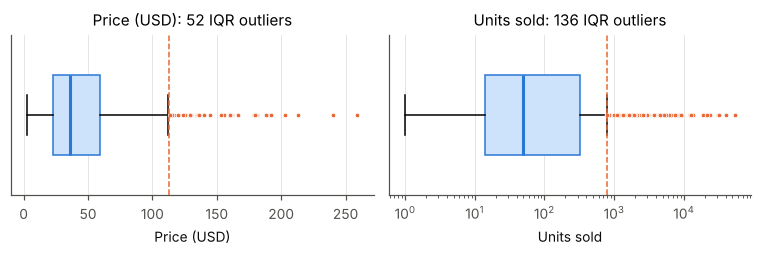

In [4]:
raw_outlier = np.zeros(len(df), dtype=bool)
for c in ['price', 'sold']:
    lo, hi = iqr_bounds(df[c])
    raw_outlier |= (df[c] < lo) | (df[c] > hi)
print(f'Products flagged on price or units sold (original scale): {raw_outlier.sum()} '
      f'({raw_outlier.mean():.1%})')

fig, axes = plt.subplots(1, 2, figsize=(7, 2.4))
for ax, (c, label) in zip(axes, [('price', 'Price (USD)'), ('sold', 'Units sold')]):
    lo, hi = iqr_bounds(df[c])
    ax.boxplot(df[c], orientation='horizontal', widths=0.5, patch_artist=True,
               boxprops=dict(facecolor='#cde2fb', edgecolor=COLORS[0]),
               medianprops=dict(color=COLORS[0], linewidth=2),
               flierprops=dict(marker='o', markersize=3, markerfacecolor=COLORS[1],
                               markeredgecolor='white', markeredgewidth=0.5))
    ax.axvline(hi, color=COLORS[1], linestyle='--', linewidth=1)
    ax.set_yticks([])
    ax.set_xlabel(label)
    if c == 'sold':
        ax.set_xscale('log')
    ax.set_title(f'{label}: {((df[c] > hi) | (df[c] < lo)).sum()} IQR outliers')
save(fig, 'outliers_iqr')

## 3.2 Effect of outlier treatment on the clustering
Four treatments are compared with K-Means (k = 4):
- **A. No transformation** – original values, scaled only;
- **B. Log transformation** – the approach used in the report;
- **C. Remove IQR outliers**, then log-transform;
- **D. Cap (winsorise) at the IQR fences**, then log-transform.

The Adjusted Rand Index (ARI) shows how far each result agrees with the chosen model (B).

In [5]:
def run_kmeans(matrix):
    Z = StandardScaler().fit_transform(matrix)
    lab = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit_predict(Z)
    return Z, lab

results = []
def record(name, Z, lab, ari):
    sizes = np.bincount(lab)
    results.append({'treatment': name, 'n products': len(lab),
                    'silhouette': round(silhouette_score(Z, lab), 3),
                    'Davies–Bouldin': round(davies_bouldin_score(Z, lab), 3),
                    'smallest cluster': sizes.min(), 'largest cluster': sizes.max(),
                    'ARI vs chosen model': ari})

# A. no transformation
ZA, lA = run_kmeans(np.c_[df['price'], df['sold'], df['available_capped']])
record('A. No transformation', ZA, lA, round(adjusted_rand_score(base_labels, lA), 3))
# B. log (chosen)
record('B. Log transformation (chosen)', X, base_labels, 1.0)
# C. remove IQR outliers, then log
keep = ~raw_outlier
ZC, lC = run_kmeans(df.loc[keep, FEATURES])
record('C. Remove IQR outliers + log', ZC, lC, round(adjusted_rand_score(base_labels[keep], lC), 3))
# D. cap at IQR fences, then log
capped = df[['price', 'sold']].copy()
for c in ['price', 'sold']:
    lo, hi = iqr_bounds(df[c]); capped[c] = df[c].clip(lo, hi)
ZD, lD = run_kmeans(np.c_[np.log1p(capped['price']), np.log1p(capped['sold']), df['log_available']])
record('D. Cap at IQR fences + log', ZD, lD, round(adjusted_rand_score(base_labels, lD), 3))

treatment_table = pd.DataFrame(results)
treatment_table

,treatment,n products,silhouette,Davies–Bouldin,smallest cluster,largest cluster,ARI vs chosen model
0,A. No transformation,994,0.494,0.724,8,519,0.210
1,B. Log transformation (chosen),994,0.300,1.028,233,267,1.000
2,C. Remove IQR outliers + log,806,0.296,1.080,167,238,0.521
3,D. Cap at IQR fences + log,994,0.306,1.056,215,315,0.756


**Reading the table.** Treatment A has the highest silhouette, but one of its clusters contains only a handful of products:
the extreme bestsellers dominate the distances, so the score is high because a few points sit far from everything else, not because
the catalogue is well segmented. Removing outliers (C) discards almost a fifth of the products – including the bestsellers that
generate most of the revenue – and changes the clusters substantially. Capping (D) gives very similar scores to the log transformation.
The log transformation (B) keeps every product, limits the influence of extremes and produces balanced, interpretable segments.

## 3.3 How well separated are the clusters? Silhouette analysis

In [6]:
sil = silhouette_samples(X, base_labels)
print(f'Mean silhouette: {sil.mean():.3f}')
print(f'Products with a negative silhouette (closer to another cluster): {(sil < 0).sum()} ({(sil < 0).mean():.1%})')
print(f'Products with silhouette below 0.1 (near a boundary): {(sil < 0.1).sum()} ({(sil < 0.1).mean():.1%})')
pd.Series(sil).groupby(df['segment'].values).agg(['mean', 'min', 'count']).round(3).loc[ORDER]

Mean silhouette: 0.300
Products with a negative silhouette (closer to another cluster): 17 (1.7%)
Products with silhouette below 0.1 (near a boundary): 132 (13.3%)


,mean,min,count
Bestsellers,0.305,-0.028,259
Premium niche,0.283,-0.007,267
Budget range,0.324,0.028,235
Low-stock slow movers,0.290,-0.072,233


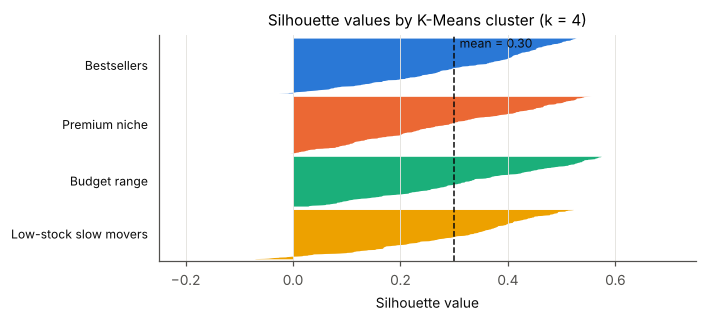

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3))
y = 0
for seg in reversed(ORDER):
    vals = np.sort(sil[df['segment'].values == seg])
    ax.fill_betweenx(np.arange(y, y + len(vals)), 0, vals, color=SEG_COLOR[seg], linewidth=0)
    ax.text(-0.27, y + len(vals) / 2, seg, ha='right', va='center', fontsize=8, color=INK)
    y += len(vals) + 15
ax.axvline(sil.mean(), color=INK, linestyle='--', linewidth=1)
ax.text(sil.mean() + 0.01, y - 5, f'mean = {sil.mean():.2f}', fontsize=8, color=INK, va='top')
ax.set_yticks([]); ax.set_xlabel('Silhouette value'); ax.set_xlim(-0.25, 0.75); ax.set_ylim(-10, y)
ax.set_title('Silhouette values by K-Means cluster (k = 4)')
save(fig, 'silhouette_plot')

## 3.4 Stability on different samples of the data
Re-running with different random seeds only shows that K-Means initialisation is consistent.
To test whether the **segments themselves** are reliable, the model was refitted on changed data:
- **Subsampling:** 50 random samples of 80% of the products; each refitted model is compared with the full model on the same products.
- **Bootstrap:** 50 samples of the same size drawn with replacement; each refitted model assigns all products, which are compared with the full model.

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
sub_ari, boot_ari = [], []
for b in range(50):
    idx = rng.choice(len(df), int(0.8 * len(df)), replace=False)
    Zs = StandardScaler().fit_transform(df.iloc[idx][FEATURES])
    lab = KMeans(n_clusters=K, n_init=20, random_state=b).fit_predict(Zs)
    sub_ari.append(adjusted_rand_score(base_labels[idx], lab))

    idx = rng.choice(len(df), len(df), replace=True)
    sc = StandardScaler().fit(df.iloc[idx][FEATURES])
    km = KMeans(n_clusters=K, n_init=20, random_state=b).fit(sc.transform(df.iloc[idx][FEATURES]))
    boot_ari.append(adjusted_rand_score(base_labels, km.predict(sc.transform(df[FEATURES]))))

stability = pd.DataFrame({'method': ['Subsampling (80%)', 'Bootstrap'],
                          'runs': [50, 50],
                          'mean ARI': [np.mean(sub_ari), np.mean(boot_ari)],
                          'minimum ARI': [np.min(sub_ari), np.min(boot_ari)],
                          '5th percentile': [np.percentile(sub_ari, 5), np.percentile(boot_ari, 5)]}).round(3)
stability

,method,runs,mean ARI,minimum ARI,5th percentile
0,Subsampling (80%),50,0.94,0.852,0.869
1,Bootstrap,50,0.87,0.707,0.764


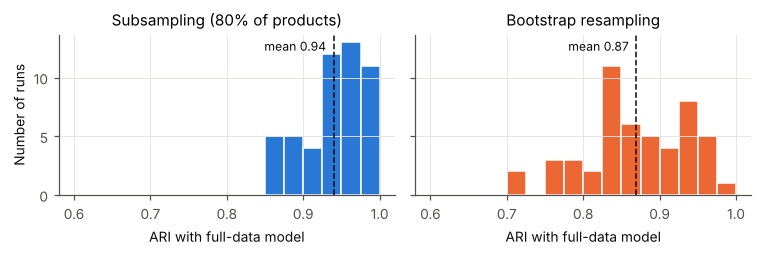

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.4), sharex=True, sharey=True)
for ax, vals, title, col in zip(axes, [sub_ari, boot_ari],
                                ['Subsampling (80% of products)', 'Bootstrap resampling'], COLORS[:2]):
    ax.hist(vals, bins=np.linspace(0.6, 1.0, 17), color=col, edgecolor='white', linewidth=1)
    ax.axvline(np.mean(vals), color=INK, linestyle='--', linewidth=1)
    ax.text(np.mean(vals) - 0.01, ax.get_ylim()[1] * 0.9, f'mean {np.mean(vals):.2f}',
            ha='right', fontsize=8, color=INK)
    ax.set_title(title); ax.set_xlabel('ARI with full-data model')
axes[0].set_ylabel('Number of runs')
save(fig, 'stability_resampling')

## 3.5 Would product size or update history add value?
**Product size** is not a separate column but can be extracted from the product description (values in ml or oz, converted to ml).
**Update history** is represented by days since the listing was last updated. Each is added to the three chosen features in turn.

In [10]:
text = df['details'].str.lower()
oz = text.str.extract(r'(\d+(?:\.\d+)?)\s*(?:fl\.?\s*)?oz')[0].astype(float)
ml = text.str.extract(r'(\d+(?:\.\d+)?)\s*ml')[0].astype(float)
df['size_ml'] = ml.fillna(oz * 29.5735)
print(f"Size found for {df['size_ml'].notna().mean():.1%} of products")
print(f"Share of products between 90 and 110 ml: {df['size_ml'].between(90, 110).mean():.1%}")
print(f"Products under 30 ml (minis / samples): {(df['size_ml'] < 30).sum()}")
print(f"Days since update missing: {df['days_since_update'].isna().mean():.1%}; "
      f"median {df['days_since_update'].median():.0f} days")
df[['size_ml', 'days_since_update', 'log_price', 'log_sold']].corr().round(2).loc[['size_ml', 'days_since_update'], ['log_price', 'log_sold']]

Size found for 93.9% of products
Share of products between 90 and 110 ml: 53.5%
Products under 30 ml (minis / samples): 80
Days since update missing: 4.7%; median 1 days


,log_price,log_sold
size_ml,0.19,0.09
days_since_update,-0.05,-0.05


In [11]:
df['log_size'] = np.log1p(df['size_ml'].fillna(df['size_ml'].median()))
df['log_days'] = np.log1p(df['days_since_update'].fillna(df['days_since_update'].median()))

rows = [{'feature set': 'Price, sales, stock (chosen)', 'silhouette': round(silhouette_score(X, base_labels), 3),
         'Davies–Bouldin': round(davies_bouldin_score(X, base_labels), 3), 'ARI vs chosen': 1.0,
         'what the new cluster captures': '–'}]
notes = {'log_size': 'a small cluster of minis / samples (median about 3 ml)',
         'log_days': 'a group of rarely updated listings (median 16 days)'}
for extra, label in [(['log_size'], '+ product size'), (['log_days'], '+ update history')]:
    Z, lab = run_kmeans(df[FEATURES + extra])
    rows.append({'feature set': label, 'silhouette': round(silhouette_score(Z, lab), 3),
                 'Davies–Bouldin': round(davies_bouldin_score(Z, lab), 3),
                 'ARI vs chosen': round(adjusted_rand_score(base_labels, lab), 3),
                 'what the new cluster captures': notes[extra[0]]})
    print(label, 'cluster medians:'); display(df.groupby(lab)[['price', 'sold', 'size_ml', 'days_since_update']].median().round(1))
extra_table = pd.DataFrame(rows)
extra_table

+ product size cluster medians:


,price,sold,size_ml,days_since_update
0,48.0,27.0,100.5,2.0
1,28.0,575.0,100.5,1.0
2,15.7,27.5,3.0,4.0
3,43.0,15.0,100.0,1.0


+ update history cluster medians:


,price,sold,size_ml,days_since_update
0,27.8,583.0,100.5,0.0
1,26.0,34.5,100.0,16.0
2,57.5,27.0,100.3,1.0
3,40.0,14.0,100.0,1.0


,feature set,silhouette,Davies–Bouldin,ARI vs chosen,what the new cluster captures
0,"Price, sales, stock (chosen)",0.300,1.028,1.000,–
1,+ product size,0.291,1.125,0.578,a small cluster of minis / samples (median abo...
2,+ update history,0.246,1.303,0.533,a group of rarely updated listings (median 16 ...


## 3.6 Compact figures for the report
The following cells regenerate the key charts at a consistent, compact size, each with a clear title.
All files are saved in the `figures/` folder.

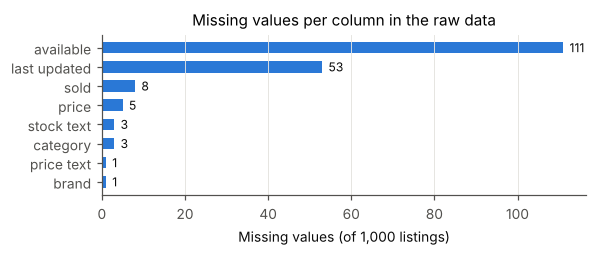

In [12]:
raw_files = [f for f in glob.glob('*.csv') if '5444' in f]
if raw_files:
    raw = pd.read_csv(raw_files[0], encoding='utf-8-sig')
    miss = raw.isna().sum().rename({'Catatory': 'category', 'priceWithCurrency': 'price text',
                                    'text': 'stock text', 'lastUpdated': 'last updated', 'Item_Name': 'brand'})
    miss = miss[miss > 0].sort_values()
    fig, ax = plt.subplots(figsize=(5.5, 2.4))
    ax.barh(miss.index, miss.values, color=COLORS[0], height=0.6)
    for i, v in enumerate(miss.values):
        ax.text(v + 1.5, i, str(v), va='center', fontsize=8, color=INK)
    ax.set_xlabel('Missing values (of 1,000 listings)'); ax.grid(axis='y', visible=False)
    ax.set_title('Missing values per column in the raw data')
    save(fig, 'missing_values')
else:
    print('Upload the raw dataset (file name containing 5444) to create this chart.')

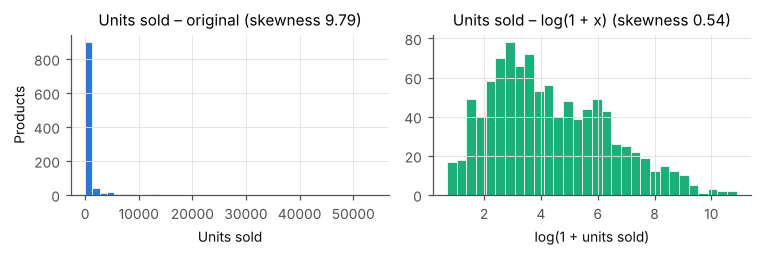

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.4))
axes[0].hist(df['sold'], bins=40, color=COLORS[0], edgecolor='white', linewidth=0.5)
axes[0].set_title(f"Units sold – original (skewness {df['sold'].skew():.2f})"); axes[0].set_xlabel('Units sold')
axes[1].hist(df['log_sold'], bins=30, color=COLORS[2], edgecolor='white', linewidth=0.5)
axes[1].set_title(f"Units sold – log(1 + x) (skewness {df['log_sold'].skew():.2f})"); axes[1].set_xlabel('log(1 + units sold)')
axes[0].set_ylabel('Products')
save(fig, 'log_transform')

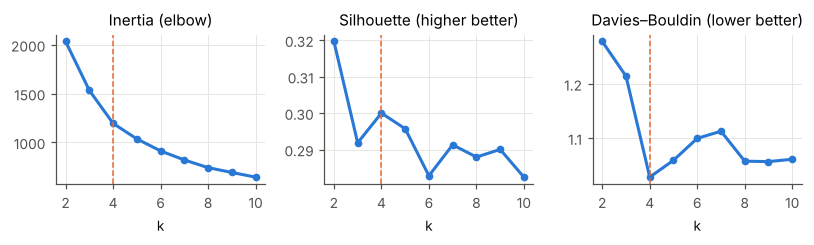

In [14]:
ks = range(2, 11)
inertia, silk, dbk = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_); silk.append(silhouette_score(X, km.labels_)); dbk.append(davies_bouldin_score(X, km.labels_))
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.3))
for ax, vals, title in zip(axes, [inertia, silk, dbk],
                           ['Inertia (elbow)', 'Silhouette (higher better)', 'Davies–Bouldin (lower better)']):
    ax.plot(list(ks), vals, marker='o', markersize=4, linewidth=2, color=COLORS[0])
    ax.axvline(K, color=COLORS[1], linestyle='--', linewidth=1)
    ax.set_title(title); ax.set_xlabel('k')
save(fig, 'kmeans_choose_k')

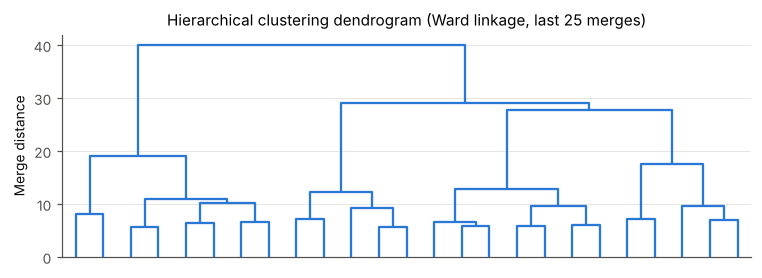

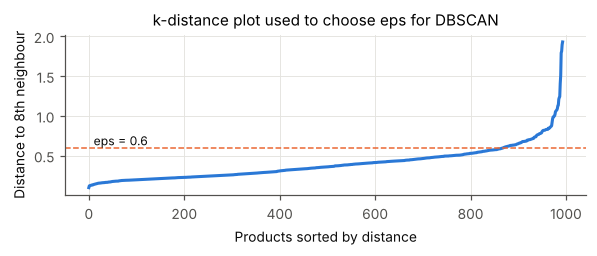

In [15]:
Z = linkage(X, method='ward')
fig, ax = plt.subplots(figsize=(7, 2.6))
dendrogram(Z, truncate_mode='lastp', p=25, no_labels=True, color_threshold=0,
           above_threshold_color=COLORS[0], ax=ax)
ax.set_ylabel('Merge distance'); ax.grid(axis='x', visible=False)
ax.set_title('Hierarchical clustering dendrogram (Ward linkage, last 25 merges)')
save(fig, 'dendrogram')

dist = np.sort(NearestNeighbors(n_neighbors=8).fit(X).kneighbors(X)[0][:, -1])
fig, ax = plt.subplots(figsize=(5.5, 2.4))
ax.plot(dist, color=COLORS[0], linewidth=2)
ax.axhline(0.6, color=COLORS[1], linestyle='--', linewidth=1)
ax.text(10, 0.63, 'eps = 0.6', fontsize=8, color=INK)
ax.set_xlabel('Products sorted by distance'); ax.set_ylabel('Distance to 8th neighbour')
ax.set_title('k-distance plot used to choose eps for DBSCAN')
save(fig, 'kdistance')

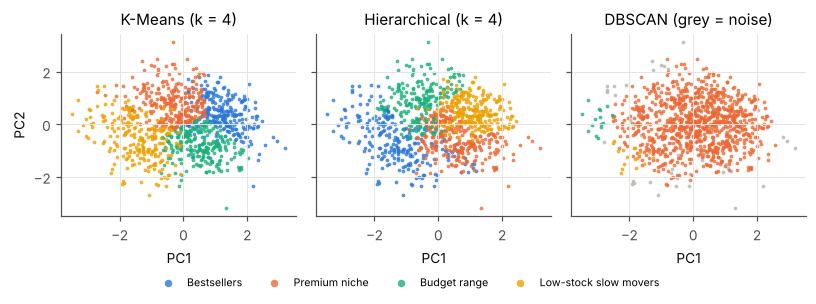

In [16]:
X_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
hc = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(X)
db = DBSCAN(eps=0.6, min_samples=8).fit_predict(X)
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.6), sharex=True, sharey=True)
for seg in ORDER:
    m = df['segment'].values == seg
    axes[0].scatter(X_pca[m, 0], X_pca[m, 1], s=6, color=SEG_COLOR[seg], linewidths=0, alpha=0.8, label=seg)
axes[0].set_title('K-Means (k = 4)'); axes[0].set_xlabel('PC1')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=4, fontsize=7, markerscale=2, bbox_to_anchor=(0.5, -0.06))
for ax, lab, title in zip(axes[1:], [hc, db], ['Hierarchical (k = 4)', 'DBSCAN (grey = noise)']):
    for i, k in enumerate(sorted(set(lab))):
        m = lab == k
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=6, color='#b5b4ad' if k == -1 else COLORS[i % len(COLORS)],
                   linewidths=0, alpha=0.8)
    ax.set_title(title); ax.set_xlabel('PC1')
axes[0].set_ylabel('PC2')
save(fig, 'model_comparison_pca')

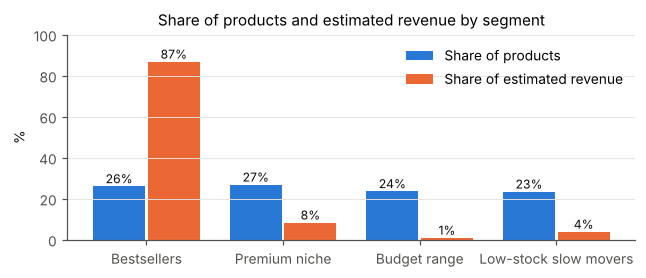

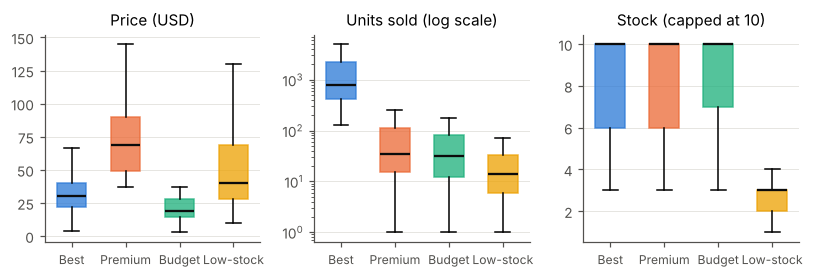

['dendrogram.png', 'kdistance.png', 'kmeans_choose_k.png', 'log_transform.png', 'missing_values.png', 'model_comparison_pca.png', 'outliers_iqr.png', 'segment_profiles.png', 'segment_revenue.png', 'silhouette_plot.png', 'stability_resampling.png']


In [17]:
order = ORDER
share = df.groupby('segment').agg(products=('price', 'size'), revenue=('revenue_est', 'sum')).loc[order]
share = share / share.sum() * 100

fig, ax = plt.subplots(figsize=(6, 2.6))
xpos = np.arange(len(order)); w = 0.38
b1 = ax.bar(xpos - w / 2 - 0.01, share['products'], w, color=COLORS[0], label='Share of products')
b2 = ax.bar(xpos + w / 2 + 0.01, share['revenue'], w, color=COLORS[1], label='Share of estimated revenue')
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f'{b.get_height():.0f}%',
                ha='center', fontsize=8, color=INK)
ax.set_xticks(xpos, order); ax.set_ylabel('%'); ax.set_ylim(0, 100); ax.grid(axis='x', visible=False)
ax.legend(loc='upper right'); ax.set_title('Share of products and estimated revenue by segment')
save(fig, 'segment_revenue')

fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.6))
for ax, col, title, logy in zip(axes, ['price', 'sold', 'available_capped'],
                                ['Price (USD)', 'Units sold (log scale)', 'Stock (capped at 10)'], [False, True, False]):
    data = [df.loc[df['segment'] == s, col] for s in order]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK, linewidth=1.5))
    for patch, c in zip(bp['boxes'], COLORS): patch.set_facecolor(c); patch.set_edgecolor(c); patch.set_alpha(0.75)
    ax.set_xticks(range(1, 5), ['Best', 'Premium', 'Budget', 'Low-stock'], fontsize=8)
    if logy: ax.set_yscale('log')
    ax.set_title(title); ax.grid(axis='x', visible=False)
save(fig, 'segment_profiles')
print(sorted(os.listdir('figures')))